# 03 — Customer RFM and Cohort Analysis

This notebook explores customer value and retention patterns using the SQL outputs generated in Notebook 02. RFM means **Recency, Frequency and Monetary value**. Cohort analysis tracks the share of an acquisition-month group that returns in later months.

These are descriptive customer analytics; they are separate from the supervised repeat-purchase model.

In [1]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "reports" / "sql").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
SQL_OUTPUT = PROJECT_ROOT / "reports" / "sql"
if not SQL_OUTPUT.exists():
    raise FileNotFoundError("Run Notebook 02 first to generate reports/sql/*.csv")

rfm = pd.read_csv(SQL_OUTPUT / "rfm_segments.csv")
cohorts = pd.read_csv(SQL_OUTPUT / "cohort_retention.csv")
concentration = pd.read_csv(SQL_OUTPUT / "revenue_concentration.csv")
display(rfm)
display(cohorts.head())
display(concentration.head())

,segment,customers,avg_customer_revenue_gbp
0,Hibernating,1640,440.198873
1,Champions,1330,8967.549974
2,Potential loyalists,1214,994.938487
3,Loyal high value,956,3017.386285
4,At risk,433,1172.596282
5,Recent customers,305,412.543770


,cohort_month,month_number,active_customers,cohort_size,retention_rate
0,2009-12-01,0,955,955,1.000000
1,2009-12-01,1,337,955,0.352880
2,2009-12-01,2,319,955,0.334031
3,2009-12-01,3,406,955,0.425131
4,2009-12-01,4,363,955,0.380105


,customer_id,revenue_gbp,customer_rank,cumulative_revenue_share
0,18102,580987.04,1,0.033438
1,14646,528602.52,2,0.063862
2,14156,313437.62,3,0.081902
3,14911,291420.81,4,0.098674
4,17450,244784.25,5,0.112763


## 1. RFM segment mix

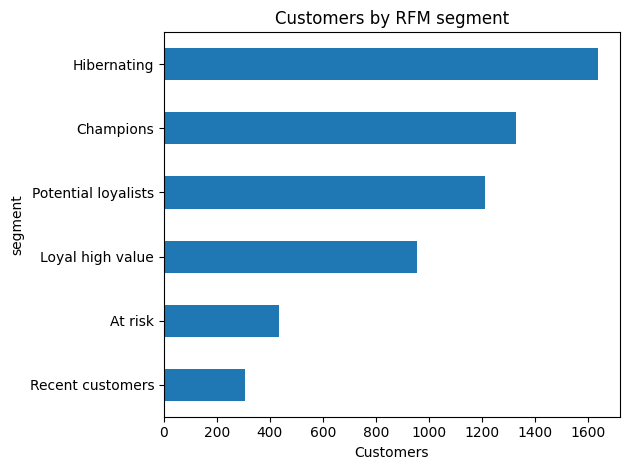

In [2]:
ax = rfm.set_index("segment")["customers"].sort_values().plot(
    kind="barh", title="Customers by RFM segment", xlabel="Customers"
)
ax.figure.tight_layout()

## 2. Cohort retention matrix

Convert the long cohort table into a matrix. Newer cohorts naturally have fewer observed months; blank cells are not zero retention.

In [3]:
retention_matrix = cohorts.pivot(
    index="cohort_month", columns="month_number", values="retention_rate"
)
display(retention_matrix.style.format("{:.1%}", na_rep="—"))

month_number,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24
cohort_month,,,,,,,,,,,,,,,,,,,,,,,,,
2009-12-01,100.0%,35.3%,33.4%,42.5%,38.0%,35.9%,37.7%,34.2%,33.6%,36.2%,42.2%,49.5%,37.6%,28.3%,24.4%,30.3%,26.3%,30.3%,28.3%,26.0%,25.5%,31.5%,30.5%,40.7%,19.7%
2010-01-01,100.0%,20.6%,31.1%,30.5%,26.4%,30.0%,25.8%,23.0%,27.9%,31.9%,30.3%,17.2%,22.2%,17.8%,18.8%,15.1%,23.5%,19.8%,18.5%,19.6%,24.3%,19.3%,24.5%,5.7%,—
2010-02-01,100.0%,23.8%,22.5%,29.1%,24.6%,20.1%,19.3%,28.6%,25.4%,27.5%,11.5%,12.6%,15.2%,17.4%,12.3%,20.1%,16.0%,16.3%,14.4%,23.0%,23.0%,16.3%,5.9%,—,—
2010-03-01,100.0%,19.0%,23.0%,24.2%,23.3%,20.3%,24.6%,30.2%,27.5%,10.8%,11.5%,14.2%,20.1%,16.3%,20.1%,16.9%,17.4%,15.6%,17.6%,20.1%,21.2%,7.9%,—,—,—
2010-04-01,100.0%,19.4%,19.4%,16.3%,18.4%,22.4%,27.6%,26.2%,10.5%,10.9%,7.5%,13.9%,13.9%,15.6%,15.6%,15.6%,13.9%,15.0%,18.0%,22.4%,5.8%,—,—,—,—
2010-05-01,100.0%,15.7%,16.9%,17.3%,17.7%,25.6%,21.3%,12.6%,5.9%,8.3%,11.4%,13.4%,15.4%,15.4%,9.8%,12.6%,13.8%,16.5%,15.4%,4.7%,—,—,—,—,—
2010-06-01,100.0%,17.4%,18.9%,20.4%,23.0%,28.5%,12.6%,8.9%,8.1%,11.9%,10.7%,13.7%,14.8%,12.2%,11.1%,12.2%,13.3%,20.4%,5.2%,—,—,—,—,—,—
2010-07-01,100.0%,15.6%,18.3%,29.6%,29.0%,14.0%,11.3%,14.5%,14.5%,11.3%,13.4%,14.5%,13.4%,13.4%,19.4%,17.2%,23.7%,8.1%,—,—,—,—,—,—,—
2010-08-01,100.0%,20.4%,29.6%,32.1%,17.3%,11.7%,9.9%,12.3%,13.6%,13.0%,13.0%,12.3%,15.4%,18.5%,17.9%,19.8%,6.8%,—,—,—,—,—,—,—,—


## 3. Revenue concentration

The SQL output ranks identified customers by cumulative revenue share. This helps quantify reliance on high-value customers.

In [4]:
top_n = min(20, len(concentration))
display(concentration.head(top_n))
if len(concentration):
    print("Revenue share contributed by top 10 customers:",
          f"{concentration.head(10)['revenue_gbp'].sum() / concentration['revenue_gbp'].sum():.1%}")

,customer_id,revenue_gbp,customer_rank,cumulative_revenue_share
0,18102,580987.04,1,0.033438
1,14646,528602.52,2,0.063862
2,14156,313437.62,3,0.081902
3,14911,291420.81,4,0.098674
4,17450,244784.25,5,0.112763
5,13694,195640.69,6,0.124023
6,17511,172132.87,7,0.133930
7,16446,168472.50,8,0.143626
8,16684,147142.77,9,0.152095
9,12415,144458.37,10,0.160409


Revenue share contributed by top 10 customers: 16.0%


## Business interpretation

Write a short memo with:
1. The largest RFM segments and what they imply.
2. Whether cohort retention appears to decay quickly or gradually.
3. The degree of customer revenue concentration.
4. One practical retention hypothesis to test—not a causal claim.